In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm

In [2]:
props=pd.read_pickle("output/all_runs_nlrV2_porportions.pkl")

In [3]:
props=props.loc[props["run"]!="augustus"]

In [4]:
props.columns

Index(['accession', 'gene', 'type', 'alternative_5end', 'reference_match',
       'alternative_3end', 'alternative_3end5end',
       'at_least_one_novel_splicesite', 'mono-exon_by_intron_retention',
       'intron_retention', '3prime_fragment', 'mono-exon', 'multi-exon',
       '5prime_fragment', 'internal_fragment',
       'combination_of_known_splicesites', 'combination_of_known_junctions',
       'run'],
      dtype='object')

In [5]:
vals=['alternative_5end', 'reference_match',
       'alternative_3end', 'alternative_3end5end',
       'at_least_one_novel_splicesite', 'mono-exon_by_intron_retention',
       'intron_retention', '3prime_fragment', 'mono-exon', 'multi-exon',
       '5prime_fragment', 'internal_fragment',
       'combination_of_known_splicesites', 'combination_of_known_junctions']

In [9]:
props_transform=props.melt(id_vars=["accession","type","gene","run"], value_vars=vals)

In [10]:
#props_transform=props_transform.loc[props_transform["variable"]=="alternative_5end"]

In [14]:
p=sns.catplot(data=props_transform, x="accession", y="value", hue="type", kind="boxen", col="run", row="variable", aspect=5, height=6, showfliers=False)

sns.move_legend(
    p, "lower center",
    bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False,
)

fig = p.fig
fig.savefig("output/subcats_proportions.png", bbox_inches='tight', dpi=200)

### Subset

In [47]:
props_transform["variable"].unique()

array(['alternative_5end', 'reference_match', 'alternative_3end',
       'alternative_3end5end', 'at_least_one_novel_splicesite',
       'mono-exon_by_intron_retention', 'intron_retention',
       '3prime_fragment', 'mono-exon', 'multi-exon', '5prime_fragment',
       'internal_fragment', 'combination_of_known_splicesites',
       'combination_of_known_junctions'], dtype=object)

In [50]:
ref_subs=props_transform.loc[(props_transform["variable"]=='alternative_5end') | (props_transform["variable"]=='reference_match') | (props_transform["variable"]=='alternative_3end') | (props_transform["variable"]=='alternative_3end5end')]
ir=props_transform.loc[props_transform["variable"]=="intron_retention"]

In [51]:
ref_subs["variable"]="reference"

/tmp/ipykernel_80013/3768606093.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ref_subs["variable"]="reference"


In [52]:
ref_subs

,accession,type,gene,run,variable,value
0,at6923,other,G1,hodgepodge,reference,0.500000
1,at6923,other,G10,hodgepodge,reference,0.010989
2,at6923,other,G100,hodgepodge,reference,0.500000
3,at6923,other,G1000,hodgepodge,reference,0.100000
4,at6923,other,G10000,hodgepodge,reference,0.000000
...,...,...,...,...,...,...
2195391,col0,other,G9995,liftoff,reference,0.016393
2195392,col0,other,G9996,liftoff,reference,0.050000
2195393,col0,other,G9997,liftoff,reference,0.000000
2195394,col0,busco,G9998,liftoff,reference,0.000000


In [76]:
ref=pd.DataFrame()
for acc in tqdm(ref_subs["accession"].unique().tolist()):
    at=ref_subs.loc[ref_subs["accession"]==acc]
    at_df=pd.DataFrame()
    for g in at.groupby(by=["gene","run"]):
        gene=pd.DataFrame({"accession":acc,
                            "type":g[1]["type"].unique(),
                            "gene":g[0][0],
                            "run":g[0][1],
                            "variable":"reference",
                            "value":g[1]["value"].sum()})
        at_df=pd.concat([at_df, gene])
    ref=pd.concat([ref,at_df])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 18/18 [06:55<00:00, 23.11s/it]


In [77]:
new=pd.concat([ref,ir])

In [78]:
new

,accession,type,gene,run,variable,value
0,at6923,other,G1,hodgepodge,reference,1.000000
0,at6923,other,G1,liftoff,reference,1.000000
0,at6923,other,G10,hodgepodge,reference,0.983516
0,at6923,other,G10,liftoff,reference,0.967033
0,at6923,other,G100,hodgepodge,reference,1.000000
...,...,...,...,...,...,...
3841938,col0,other,G9995,liftoff,intron_retention,0.000000
3841939,col0,other,G9996,liftoff,intron_retention,0.000000
3841940,col0,other,G9997,liftoff,intron_retention,0.125000
3841941,col0,busco,G9998,liftoff,intron_retention,0.125000


In [93]:
#sns.set(font_scale=2.5)
sns.set(style='white', font_scale=2.5)


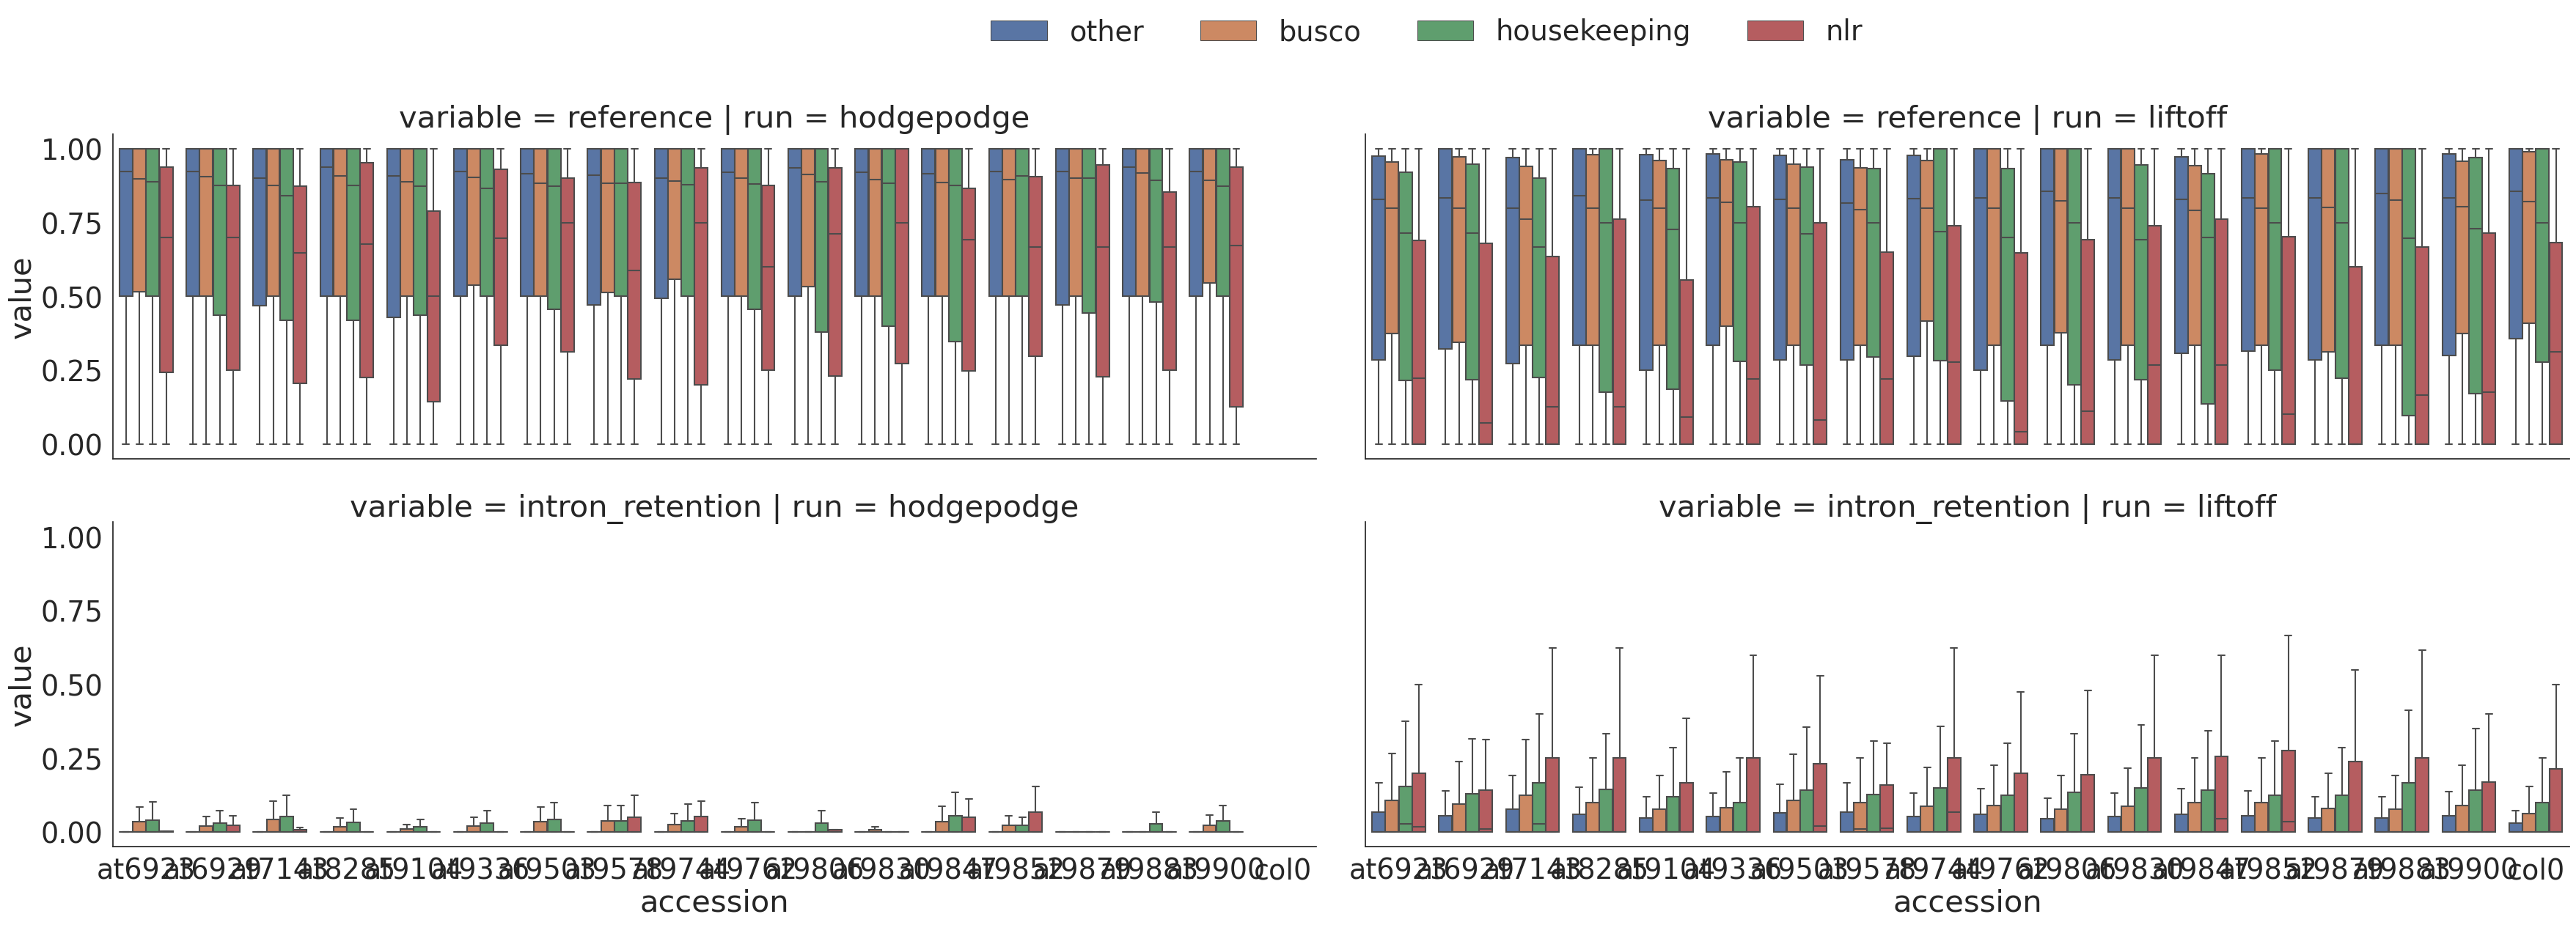

In [95]:
p=sns.catplot(data=new, x="accession", y="value", hue="type", kind="box", col="run", row="variable", aspect=3, height=6, showfliers=False)

sns.move_legend(
    p, "lower center",
    bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False,
)

fig = p.fig
fig.savefig("output/ref-ir_proportions.png", bbox_inches='tight', dpi=200)

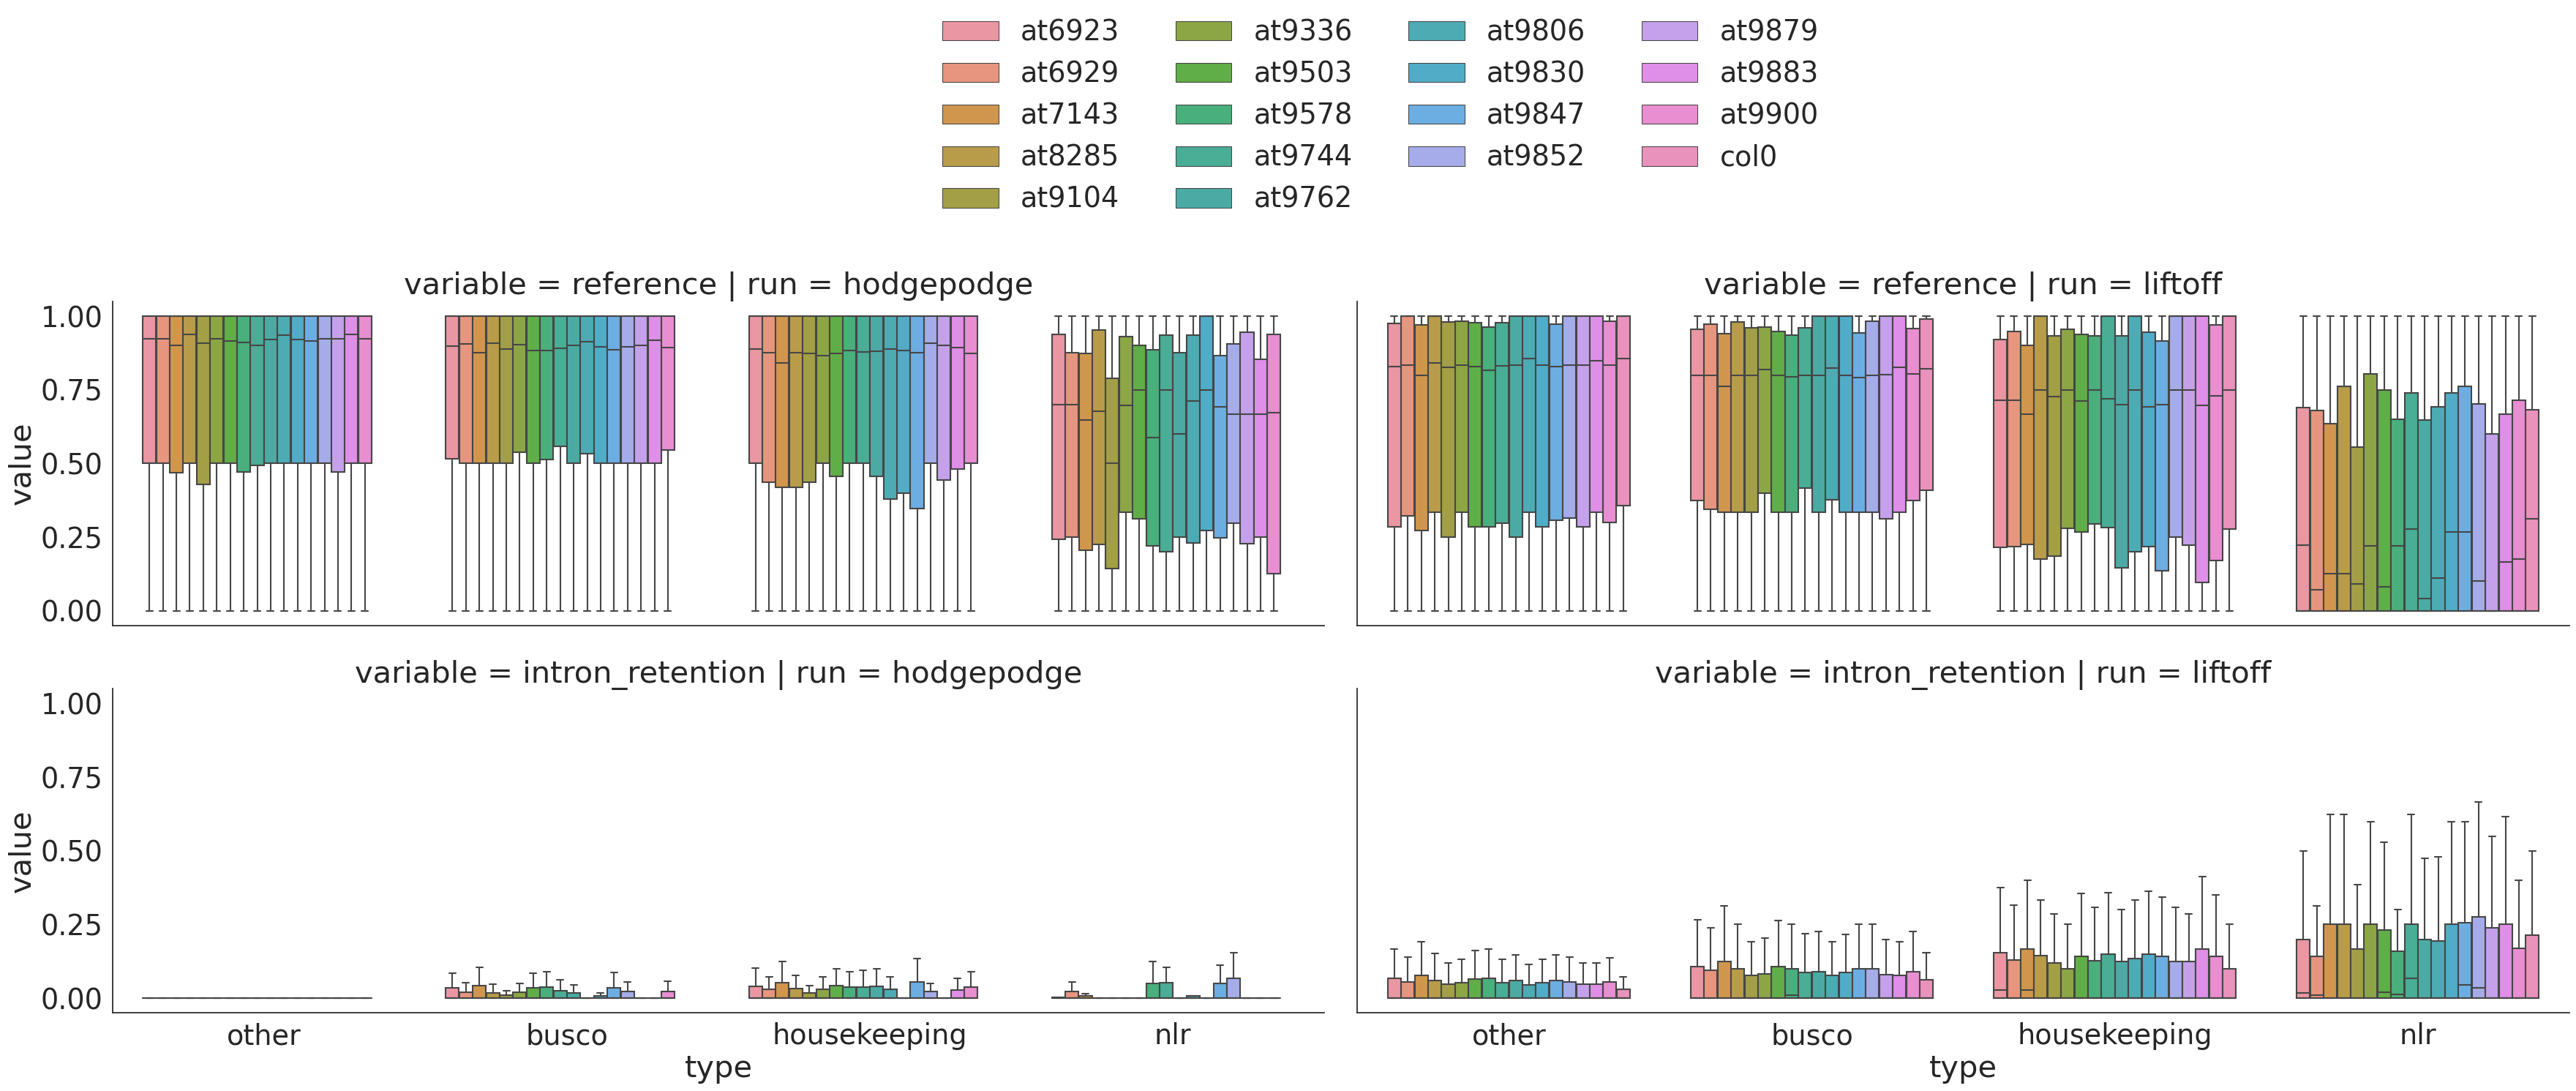

In [97]:
p=sns.catplot(data=new, x="type", y="value", hue="accession", kind="box", col="run", row="variable", aspect=3, height=6, showfliers=False)

sns.move_legend(
    p, "lower center",
    bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False,
)

fig = p.fig
fig.savefig("output/ref-ir_proportions.png", bbox_inches='tight', dpi=200)